<a href="https://colab.research.google.com/github/JimmyApron/feature-engineering-assignment/blob/main/feature_engineering_assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

STEP 01. 데이터 준비

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# 데이터 업로드
uploaded = files.upload()

# 데이터 불러오기
df = pd.read_csv("train.csv")

# 데이터 기본 정보 확인
print("데이터 크기:", df.shape)
print("\n컬럼 정보")
df.info()

print("\n상위 5개 데이터")
display(df.head())

print("\n기초 통계량")
display(df.describe(include="all"))

print("\n결측치 개수")
print(df.isnull().sum())

# 타겟 변수 확인
print("\n생존 여부 분포")
print(df["Survived"].value_counts())


Saving train.csv to train (5).csv
데이터 크기: (891, 12)

컬럼 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

상위 5개 데이터


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



기초 통계량


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN



결측치 개수
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

생존 여부 분포
Survived
0    549
1    342
Name: count, dtype: int64


STEP 02. 탐색적 데이터 분석 (EDA)

Cabin          77.104377
Age            19.865320
Embarked        0.224467
PassengerId     0.000000
Name            0.000000
Pclass          0.000000
Survived        0.000000
Sex             0.000000
Parch           0.000000
SibSp           0.000000
Fare            0.000000
Ticket          0.000000
dtype: float64


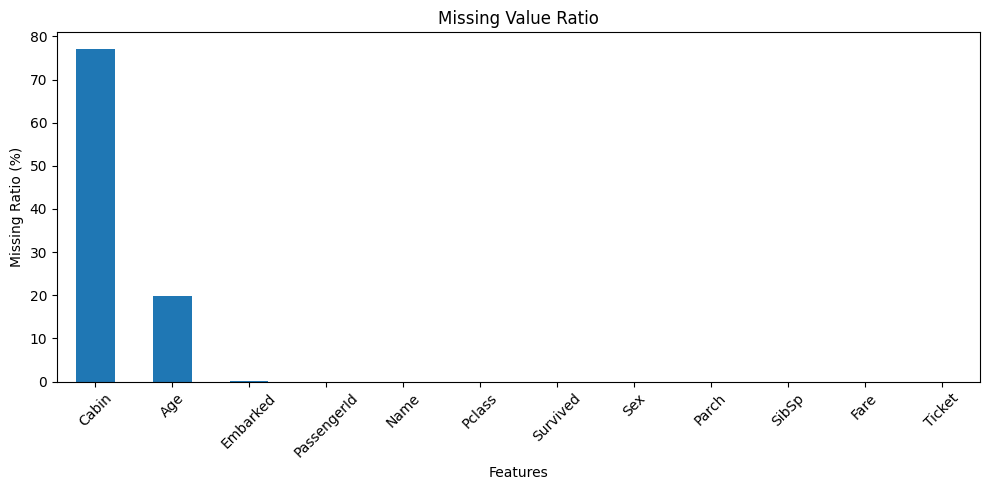

In [54]:
# 1. 결측치 비율 분석
# 컬럼별 결측치 비율
missing = df.isnull().mean() * 100
print(missing.sort_values(ascending=False))

# 결측치 비율 시각화
plt.figure(figsize=(10, 5))
missing.sort_values(ascending=False).plot(kind="bar")
plt.title("Missing Value Ratio")
plt.ylabel("Missing Ratio (%)")
plt.xlabel("Features")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

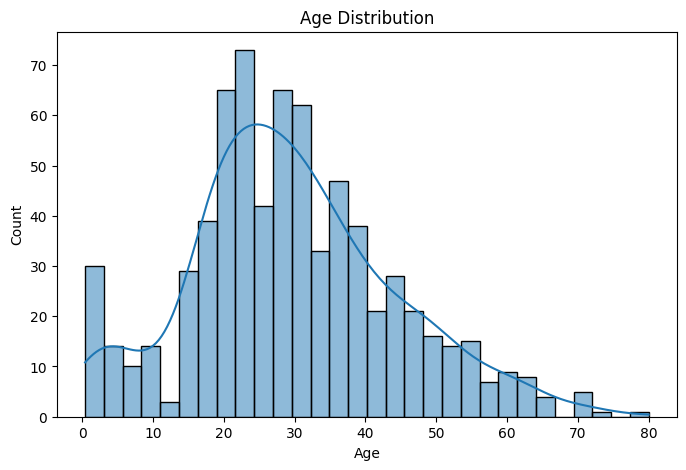

In [55]:
# 2. Histogram — 나이 분포
# 나이 분포 확인
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

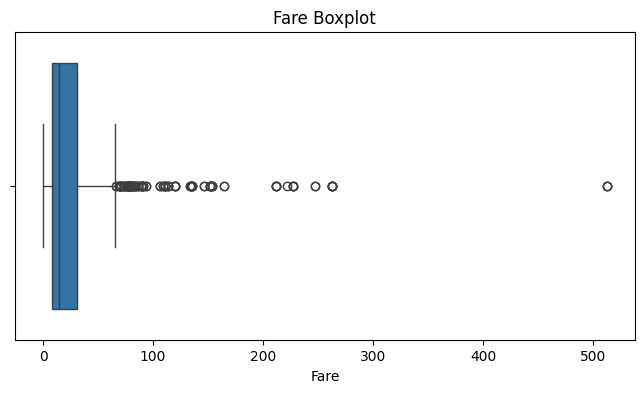

이상치 개수: 116
이상치 비율: 13.02 %


In [56]:
# 3. Boxplot — 운임 이상치 탐색
# 운임 분포와 이상치 확인
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Fare"])
plt.title("Fare Boxplot")
plt.xlabel("Fare")
plt.show()

# IQR을 이용한 이상치 개수 확인
Q1 = df["Fare"].quantile(0.25)
Q3 = df["Fare"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[(df["Fare"] < lower) | (df["Fare"] > upper)]

print("이상치 개수:", len(outliers))
print("이상치 비율:", round(len(outliers) / len(df) * 100, 2), "%")

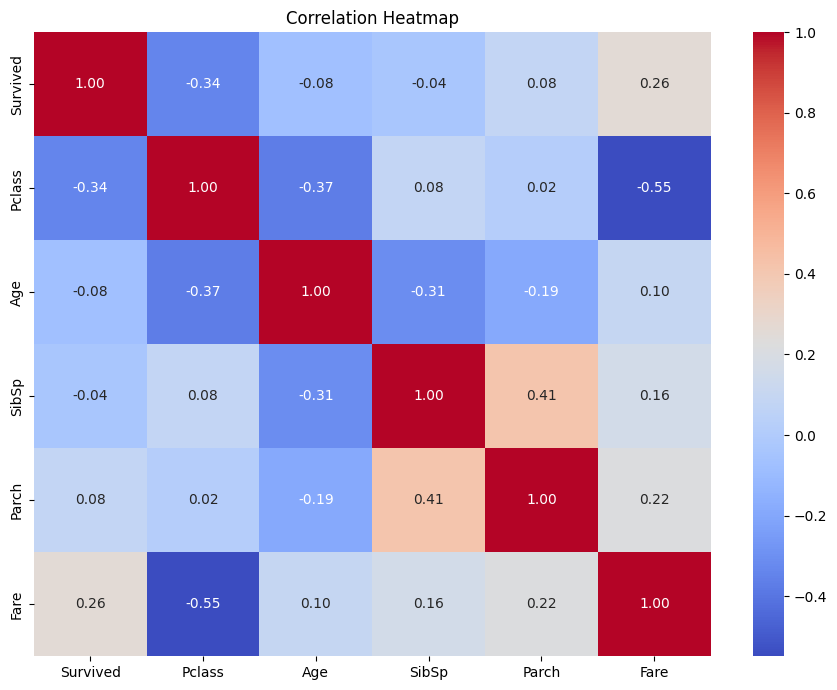

In [57]:
# 4. Heatmap — 상관관계 분석
# 수치형 변수 간 상관관계
numeric_df = df.select_dtypes(include=["int64", "float64"])
numeric_df = numeric_df.drop(columns=["PassengerId"])

plt.figure(figsize=(9, 7))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

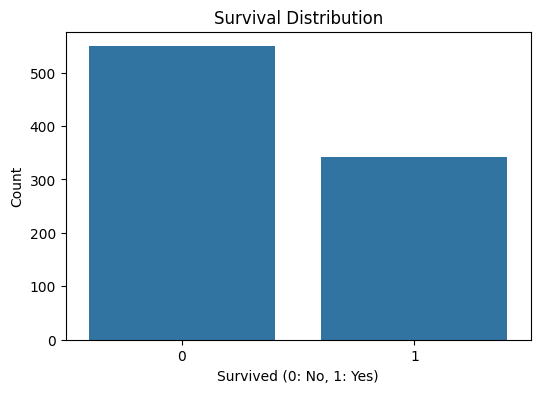


성별 생존율
Sex
female    0.742038
male      0.188908
Name: Survived, dtype: float64


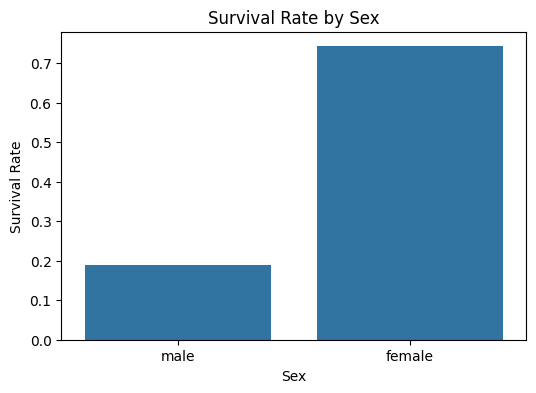

In [58]:
# 5. Countplot — 타겟 변수 분포
# 생존 여부 분포
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="Survived")
plt.title("Survival Distribution")
plt.xlabel("Survived (0: No, 1: Yes)")
plt.ylabel("Count")
plt.show()

# 성별에 따른 생존율
survival_by_sex = df.groupby("Sex")["Survived"].mean()
print("\n성별 생존율")
print(survival_by_sex)

plt.figure(figsize=(6, 4))
sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)
plt.title("Survival Rate by Sex")
plt.ylabel("Survival Rate")
plt.show()

STEP 03. 특성 공학 파이프라인 구현 /
반드시 비교 실험 수행

In [59]:
from sklearn.model_selection import train_test_split

# 원본 데이터 복사
data = df.copy()

# 파생 변수 생성
data["FamilySize"] = data["SibSp"] + data["Parch"] + 1
data["FarePerPerson"] = data["Fare"] / data["FamilySize"]

# 모델에 사용할 변수 선택
features = [
    "Pclass", "Sex", "Age", "SibSp", "Parch",
    "Fare", "Embarked", "FamilySize", "FarePerPerson"
]

X = data[features].copy()
y = data["Survived"]

# 객실 등급을 범주형으로 변환
X["Pclass"] = X["Pclass"].astype(str)

# 학습 데이터와 테스트 데이터 분리 (8:2)
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("전체 데이터:", X.shape)
print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

print("\n파생 변수 확인")
display(data[["SibSp", "Parch", "FamilySize", "Fare", "FarePerPerson"]].head())

전체 데이터: (891, 9)
학습 데이터: (712, 9)
테스트 데이터: (179, 9)

파생 변수 확인


,SibSp,Parch,FamilySize,Fare,FarePerPerson
0,1,0,2,7.2500,3.62500
1,1,0,2,71.2833,35.64165
2,0,0,1,7.9250,7.92500
3,1,0,2,53.1000,26.55000
4,0,0,1,8.0500,8.05000


In [60]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import SelectKBest, f_classif

# 변수 구분
numeric_features = [
    "Age", "SibSp", "Parch", "Fare",
    "FamilySize", "FarePerPerson"
]
categorical_features = ["Pclass", "Sex", "Embarked"]

# 전처리 파이프라인 생성
def make_preprocessor(impute_method, encoding_method, scaling_method):

    # 결측치 처리 및 스케일링
    scalers = {
        "standard": StandardScaler(),
        "minmax": MinMaxScaler(),
        "robust": RobustScaler()
    }

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy=impute_method)),
        ("scaler", scalers[scaling_method])
    ])

    # 범주형 인코딩
    if encoding_method == "onehot":
        encoder = OneHotEncoder(
            handle_unknown="ignore", sparse_output=False
        )
    else:
        encoder = OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", encoder)
    ])

    # 수치형과 범주형 전처리 결합
    preprocessor = ColumnTransformer([
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    return preprocessor

print("전처리 파이프라인 생성 함수 준비 완료")

전처리 파이프라인 생성 함수 준비 완료


In [61]:
# 실험 조건 설정
experiments = {
    "Exp-1": {
        "impute": "mean",
        "encoding": "onehot",
        "scaling": "standard",
        "selection": False
    },
    "Exp-2": {
        "impute": "median",
        "encoding": "ordinal",
        "scaling": "minmax",
        "selection": True
    },
    "Exp-3": {
        "impute": "most_frequent",
        "encoding": "onehot",
        "scaling": "robust",
        "selection": True
    }
}

# 실험별 설정 확인
display(pd.DataFrame(experiments).T)

,impute,encoding,scaling,selection
Exp-1,mean,onehot,standard,False
Exp-2,median,ordinal,minmax,True
Exp-3,most_frequent,onehot,robust,True


In [62]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# 비교할 모델
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, solver="liblinear"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, random_state=42
    )
}

STEP 04. 변수 선택 (Feature Selection)

In [63]:
from sklearn.base import clone

selection_results = []

# 변수 선택 여부에 따른 성능 비교
for model_name, model in models.items():
    for use_selection in [False, True]:

        steps = [
            ("preprocessor", make_preprocessor(
                "mean", "onehot", "standard"
            ))
        ]

        if use_selection:
            steps.append((
                "selection", SelectKBest(f_classif, k=8)
            ))

        steps.append(("model", clone(model)))
        pipeline = Pipeline(steps)

        pipeline.fit(X_train, y_train)

        train_pred = pipeline.predict(X_train)
        test_pred = pipeline.predict(X_test)

        selection_results.append({
            "Model": model_name,
            "Feature Selection": "Top 8" if use_selection else "All",
            "Train F1": f1_score(y_train, train_pred),
            "Test F1": f1_score(y_test, test_pred),
            "Accuracy": accuracy_score(y_test, test_pred)
        })

        # 선택된 변수 확인
        if use_selection and model_name == "Random Forest":
            feature_names = pipeline.named_steps[
                "preprocessor"
            ].get_feature_names_out()

            selected = pipeline.named_steps[
                "selection"
            ].get_support()

            print("선택된 상위 8개 특성:")
            print(feature_names[selected])

selection_df = pd.DataFrame(selection_results)
display(selection_df.round(4))

선택된 상위 8개 특성:
['num__Fare' 'num__FarePerPerson' 'cat__Pclass_1' 'cat__Pclass_3'
 'cat__Sex_female' 'cat__Sex_male' 'cat__Embarked_C' 'cat__Embarked_S']


,Model,Feature Selection,Train F1,Test F1,Accuracy
0,Logistic Regression,All,0.7380,0.7188,0.7989
1,Logistic Regression,Top 8,0.7063,0.7023,0.7821
2,Random Forest,All,0.9778,0.7259,0.7933
3,Random Forest,Top 8,0.9053,0.7111,0.7821


STEP 05. 모델 학습 및 평가

In [64]:
results = []

# 모델 성능 평가
def evaluate(name, model_name, pipeline, X_tr, X_te):
    pipeline.fit(X_tr, y_train)

    pred = pipeline.predict(X_te)
    prob = pipeline.predict_proba(X_te)[:, 1]
    train_pred = pipeline.predict(X_tr)

    results.append({
        "Experiment": name,
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Train F1": f1_score(y_train, train_pred)
    })

# Base: 결측치 없는 수치형 변수만 사용
base_features = [
    "SibSp", "Parch", "Fare",
    "FamilySize", "FarePerPerson"
]

for model_name, model in models.items():
    base_pipeline = Pipeline([
        ("model", model)
    ])

    evaluate(
        "Base", model_name, base_pipeline,
        X_train[base_features], X_test[base_features]
    )

# Exp-1 ~ Exp-3
for exp_name, config in experiments.items():

    preprocessor = make_preprocessor(
        config["impute"],
        config["encoding"],
        config["scaling"]
    )

    for model_name, model in models.items():
        steps = [("preprocessor", preprocessor)]

        # 변수 선택 적용
        if config["selection"]:
            steps.append((
                "selection", SelectKBest(score_func=f_classif, k=8)
            ))

        steps.append(("model", model))

        pipeline = Pipeline(steps)

        evaluate(
            exp_name, model_name, pipeline,
            X_train, X_test
        )

# 결과 비교
results_df = pd.DataFrame(results)

print("실험별 성능 비교")
display(results_df.round(4))

실험별 성능 비교


,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
0,Base,Logistic Regression,0.6480,0.6250,0.2174,0.3226,0.6594,0.4199
1,Base,Random Forest,0.5810,0.4571,0.4638,0.4604,0.6371,0.7985
2,Exp-1,Logistic Regression,0.7989,0.7797,0.6667,0.7188,0.8437,0.7380
3,Exp-1,Random Forest,0.7933,0.7424,0.7101,0.7259,0.8250,0.9778
4,Exp-2,Logistic Regression,0.7933,0.7667,0.6667,0.7132,0.8489,0.7335
5,Exp-2,Random Forest,0.7933,0.7500,0.6957,0.7218,0.8164,0.9778
6,Exp-3,Logistic Regression,0.7821,0.7419,0.6667,0.7023,0.8147,0.7063
7,Exp-3,Random Forest,0.7821,0.7273,0.6957,0.7111,0.8102,0.9053


In [65]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# 5-Fold 교차검증
cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

# 모델별 탐색 범위
param_grids = {
    "Logistic Regression": {
        "selection__k": [8, "all"],
        "model__C": [0.1, 1.0, 10.0]
    },
    "Random Forest": {
        "selection__k": [8, "all"],
        "model__max_depth": [4, 8, None],
        "model__min_samples_leaf": [1, 3]
    }
}

best_grids = {}
grid_results = []

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", make_preprocessor(
            "mean", "onehot", "standard"
        )),
        ("selection", SelectKBest(f_classif, k=8)),
        ("model", clone(model))
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[model_name],
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(X_train, y_train)
    best_grids[model_name] = grid

    best_model = grid.best_estimator_
    pred = best_model.predict(X_test)
    prob = best_model.predict_proba(X_test)[:, 1]

    grid_results.append({
        "Experiment": "GridSearchCV",
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Train F1": f1_score(
            y_train, best_model.predict(X_train)
        ),
        "CV F1": grid.best_score_
    })

    print(f"\n{model_name}")
    print("최적 파라미터:", grid.best_params_)
    print("교차검증 F1:", round(grid.best_score_, 4))
    print("테스트 F1:", round(f1_score(y_test, pred), 4))

grid_df = pd.DataFrame(grid_results)
display(grid_df.round(4))


Logistic Regression
최적 파라미터: {'model__C': 1.0, 'selection__k': 'all'}
교차검증 F1: 0.7292
테스트 F1: 0.7188

Random Forest
최적 파라미터: {'model__max_depth': 8, 'model__min_samples_leaf': 1, 'selection__k': 'all'}
교차검증 F1: 0.764
테스트 F1: 0.7419


,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1,CV F1
0,GridSearchCV,Logistic Regression,0.7989,0.7797,0.6667,0.7188,0.8437,0.7380,0.7292
1,GridSearchCV,Random Forest,0.8212,0.8364,0.6667,0.7419,0.8403,0.8975,0.7640


,Feature,Importance
9,cat__Sex_female,0.193364
10,cat__Sex_male,0.175064
5,num__FarePerPerson,0.141511
0,num__Age,0.138045
3,num__Fare,0.121948
8,cat__Pclass_3,0.050091
4,num__FamilySize,0.048897
6,cat__Pclass_1,0.030553
1,num__SibSp,0.026442
2,num__Parch,0.021124


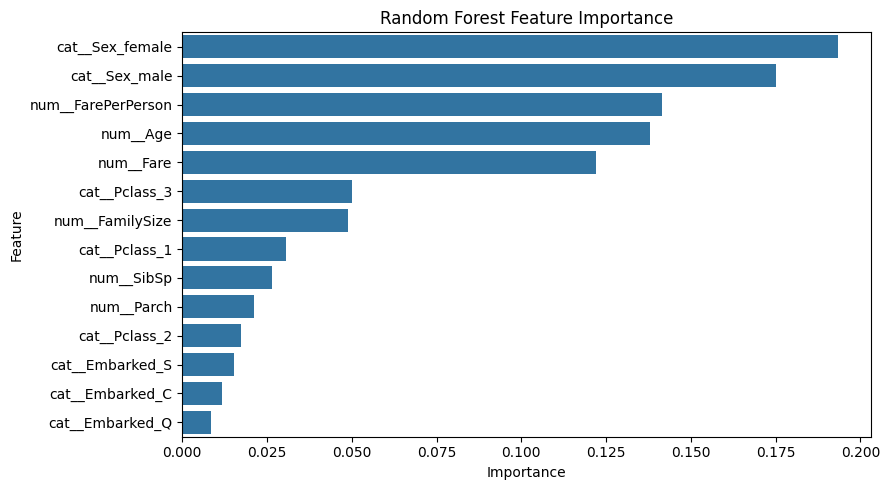

In [66]:
# GridSearchCV로 찾은 최적 Random Forest
best_rf = best_grids["Random Forest"].best_estimator_

# 전처리된 특성 이름
feature_names = best_rf.named_steps[
    "preprocessor"
].get_feature_names_out()

# 실제 모델에 사용된 특성
selected = best_rf.named_steps["selection"].get_support()
feature_names = feature_names[selected]

# 변수 중요도
importances = best_rf.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df)

# 중요도 그래프
plt.figure(figsize=(9, 5))
sns.barplot(
    data=importance_df,
    x="Importance", y="Feature"
)
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

,Feature,Importance
1,Sex,0.2643
0,Pclass,0.0796
2,Age,0.0595
5,Fare,0.0547
6,Embarked,0.0509
4,Parch,0.0326
8,FarePerPerson,0.0298
7,FamilySize,0.0258
3,SibSp,0.0184


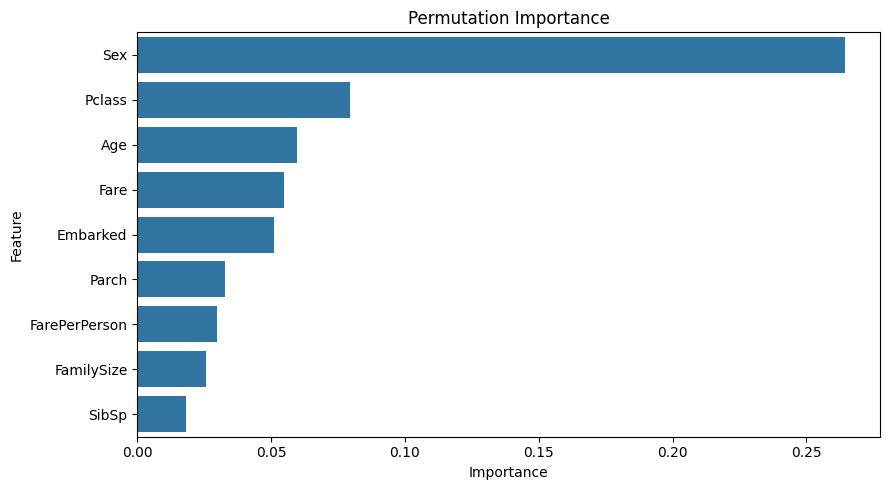

In [67]:
from sklearn.inspection import permutation_importance

# 특성을 섞었을 때 F1 감소량 확인
perm = permutation_importance(
    best_rf,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=10,
    random_state=42
)

perm_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm.importances_mean
}).sort_values("Importance", ascending=False)

display(perm_df.round(4))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=perm_df,
    x="Importance", y="Feature"
)
plt.title("Permutation Importance")
plt.tight_layout()
plt.show()

In [68]:
!pip -q install shap

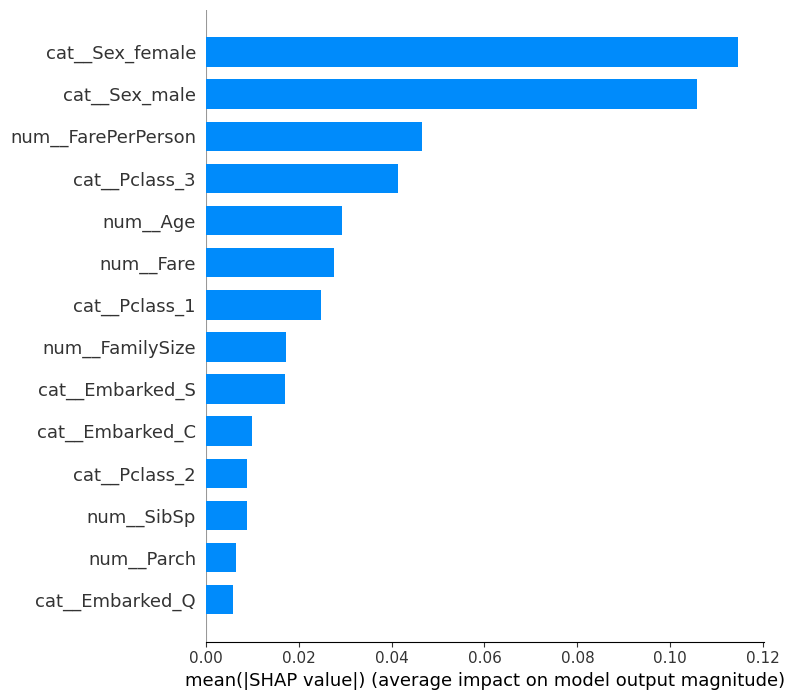

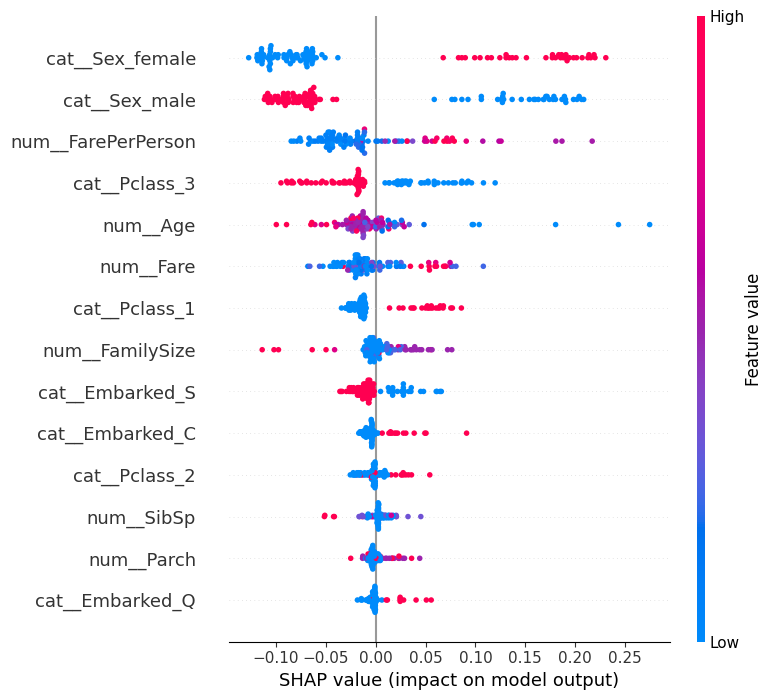

In [69]:
import shap

# 테스트 데이터 일부 사용
X_sample = X_test.iloc[:100].copy()

# 학습된 전처리와 변수 선택 적용
X_processed = best_rf.named_steps[
    "preprocessor"
].transform(X_sample)

X_selected = best_rf.named_steps[
    "selection"
].transform(X_processed)

X_shap = pd.DataFrame(
    X_selected,
    columns=feature_names
)

# SHAP 값 계산
explainer = shap.TreeExplainer(
    best_rf.named_steps["model"]
)

shap_values = explainer.shap_values(X_shap)

# 생존(1) 클래스의 SHAP 값 추출
if isinstance(shap_values, list):
    shap_positive = shap_values[1]
elif shap_values.ndim == 3:
    shap_positive = shap_values[:, :, 1]
else:
    shap_positive = shap_values

# 전체 특성의 평균 영향력
shap.summary_plot(
    shap_positive, X_shap, plot_type="bar"
)

# 특성별 영향 방향과 크기
shap.summary_plot(
    shap_positive, X_shap
)

In [70]:
!pip -q install "flaml[automl]" lightgbm

In [71]:
from flaml import AutoML

# AutoML 설정
automl = AutoML()

automl.fit(
    X_train=X_train.copy(),
    y_train=y_train,
    task="classification",
    metric="f1",
    time_budget=60,
    estimator_list=["lgbm", "rf", "extra_tree"],
    eval_method="cv",
    n_splits=5,
    seed=42,
    verbose=0
)

# 최적 모델 확인
print("최적 모델:", automl.best_estimator)
print("최적 설정:", automl.best_config)

# 테스트 데이터 평가
auto_pred = automl.predict(X_test)
auto_prob = automl.predict_proba(X_test)[:, 1]

auto_results = [{
    "Experiment": "AutoML",
    "Model": "FLAML (" + automl.best_estimator + ")",
    "Accuracy": accuracy_score(y_test, auto_pred),
    "Precision": precision_score(y_test, auto_pred),
    "Recall": recall_score(y_test, auto_pred),
    "F1": f1_score(y_test, auto_pred),
    "ROC-AUC": roc_auc_score(y_test, auto_prob),
    "Train F1": f1_score(
        y_train, automl.predict(X_train)
    )
}]

auto_df = pd.DataFrame(auto_results)
display(auto_df.round(4))

최적 모델: lgbm
최적 설정: {'n_estimators': 13, 'num_leaves': 16, 'min_child_samples': 18, 'learning_rate': np.float64(0.4385471446817659), 'log_max_bin': 8, 'colsample_bytree': 1.0, 'reg_alpha': np.float64(0.0944116744587426), 'reg_lambda': np.float64(0.011424533702089271)}


,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
0,AutoML,FLAML (lgbm),0.7989,0.7797,0.6667,0.7188,0.8126,0.8868


,Condition,Model,F1,Accuracy
0,Mean,Logistic Regression,0.7188,0.7989
1,Mean,Random Forest,0.7259,0.7933
2,Median,Logistic Regression,0.7188,0.7989
3,Median,Random Forest,0.7368,0.8045
4,Most Frequent,Logistic Regression,0.7188,0.7989
5,Most Frequent,Random Forest,0.7407,0.8045
6,Ordinal,Logistic Regression,0.7132,0.7933
7,Ordinal,Random Forest,0.7368,0.8045
8,MinMax,Logistic Regression,0.7031,0.7877
9,MinMax,Random Forest,0.7259,0.7933


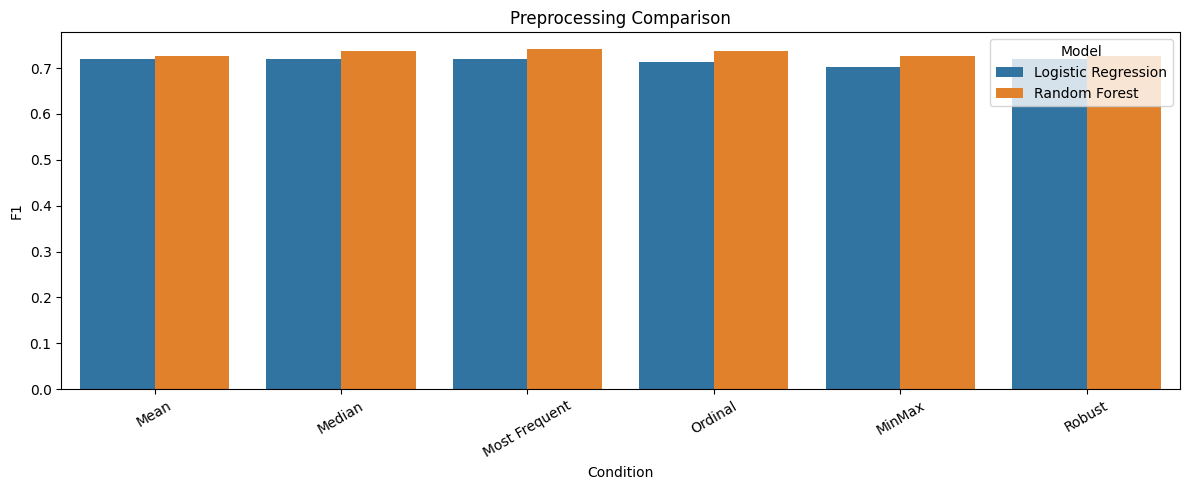

In [72]:
# 한 가지 조건씩 변경해서 비교
control_settings = {
    "Mean": ("mean", "onehot", "standard"),
    "Median": ("median", "onehot", "standard"),
    "Most Frequent": ("most_frequent", "onehot", "standard"),
    "Ordinal": ("mean", "ordinal", "standard"),
    "MinMax": ("mean", "onehot", "minmax"),
    "Robust": ("mean", "onehot", "robust")
}

control_results = []

for condition, settings in control_settings.items():
    for model_name, model in models.items():

        pipeline = Pipeline([
            ("preprocessor", make_preprocessor(*settings)),
            ("model", clone(model))
        ])

        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_test)

        control_results.append({
            "Condition": condition,
            "Model": model_name,
            "F1": f1_score(y_test, pred),
            "Accuracy": accuracy_score(y_test, pred)
        })

control_df = pd.DataFrame(control_results)
display(control_df.round(4))

# 실험 결과 시각화
plt.figure(figsize=(12, 5))
sns.barplot(
    data=control_df,
    x="Condition", y="F1", hue="Model"
)
plt.title("Preprocessing Comparison")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [73]:
derived_results = []

for model_name, model in models.items():
    for use_derived in [False, True]:

        preprocessor = make_preprocessor(
            "mean", "onehot", "standard"
        )

        if not use_derived:
            # 파생 변수 2개 제외
            old_numeric = [
                "Age", "SibSp", "Parch", "Fare"
            ]

            preprocessor = ColumnTransformer([
                ("num", preprocessor.transformers[0][1], old_numeric),
                ("cat", preprocessor.transformers[1][1],
                 categorical_features)
            ])

        pipeline = Pipeline([
            ("preprocessor", preprocessor),
            ("model", clone(model))
        ])

        pipeline.fit(X_train, y_train)
        pred = pipeline.predict(X_test)

        derived_results.append({
            "Model": model_name,
            "Derived Features": "Yes" if use_derived else "No",
            "F1": f1_score(y_test, pred),
            "Accuracy": accuracy_score(y_test, pred)
        })

derived_df = pd.DataFrame(derived_results)
display(derived_df.round(4))

,Model,Derived Features,F1,Accuracy
0,Logistic Regression,No,0.7244,0.8045
1,Logistic Regression,Yes,0.7188,0.7989
2,Random Forest,No,0.7424,0.8101
3,Random Forest,Yes,0.7259,0.7933


In [74]:
# 전체 성능 비교표
final_results = pd.concat([
    results_df,
    grid_df,
    auto_df
], ignore_index=True)

columns = [
    "Experiment", "Model",
    "Accuracy", "Precision", "Recall",
    "F1", "ROC-AUC", "Train F1"
]

final_results = final_results[columns]

# F1-score 기준 정렬
final_results = final_results.sort_values(
    "F1", ascending=False
)

print("최종 성능 비교")
display(final_results.round(4))

# 최고 성능 모델 확인
print("\nF1-score 최고 모델")
display(final_results.head(1))

최종 성능 비교


,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
9,GridSearchCV,Random Forest,0.8212,0.8364,0.6667,0.7419,0.8403,0.8975
3,Exp-1,Random Forest,0.7933,0.7424,0.7101,0.7259,0.8250,0.9778
5,Exp-2,Random Forest,0.7933,0.7500,0.6957,0.7218,0.8164,0.9778
10,AutoML,FLAML (lgbm),0.7989,0.7797,0.6667,0.7188,0.8126,0.8868
8,GridSearchCV,Logistic Regression,0.7989,0.7797,0.6667,0.7188,0.8437,0.7380
2,Exp-1,Logistic Regression,0.7989,0.7797,0.6667,0.7188,0.8437,0.7380
4,Exp-2,Logistic Regression,0.7933,0.7667,0.6667,0.7132,0.8489,0.7335
7,Exp-3,Random Forest,0.7821,0.7273,0.6957,0.7111,0.8102,0.9053
6,Exp-3,Logistic Regression,0.7821,0.7419,0.6667,0.7023,0.8147,0.7063
1,Base,Random Forest,0.5810,0.4571,0.4638,0.4604,0.6371,0.7985



F1-score 최고 모델


,Experiment,Model,Accuracy,Precision,Recall,F1,ROC-AUC,Train F1
9,GridSearchCV,Random Forest,0.821229,0.836364,0.666667,0.741935,0.840316,0.897485
